# Python Machine Learning client for SAP HANA, release 2.28 enhancements sample notebook

The changelog of enhancements with the release version 2.28 can be found [in the documentation](https://help.sap.com/doc/cd94b08fe2e041c2ba778374572ddba9/2026_1_QRC/en-US/change_log.html), and are summaried below  <br><br>
__New functions__<br>
    - Added dataframe `info()` function to get table overview information. <br>
    - Added PAL CrossEncoder function `hana_ml.text.pal_cross_encoder.PALCrossEncoder`. <br>
    - Added text log parse function (BRAIN) `hana_ml.text.tm.text_log_parse`. <br>

__Enhanced functions__<br>
    - Added __parameter search__ support for [MLPMultiTaskClassifier](https://help.sap.com/doc/cd94b08fe2e041c2ba778374572ddba9/2026_1_QRC/en-US/pal/algorithms/hana_ml.algorithms.pal.neural_network.MLPMultiTaskClassifier.html#hana_ml.algorithms.pal.neural_network.MLPMultiTaskClassifier) and [MLPMultiTaskRegressor](https://help.sap.com/doc/cd94b08fe2e041c2ba778374572ddba9/2026_1_QRC/en-US/pal/algorithms/hana_ml.algorithms.pal.neural_network.MLPMultiTaskRegressor.html#hana_ml.algorithms.pal.neural_network.MLPMultiTaskRegressor) <br>
    - Text tokenizer with enhanced the regex support. <br>
    - AutoML time series support of confidence and prediction intervals. <br>
    - AutoML support for raw text colum proprocessing operators. <br>
    - AutoML TargetEncoder operator information enhanced for display in visualizer. <br>
    - AutoML support for loading progress details on request for massive automl scenarios. <br>
    - Time Series report with enhanced visualization for massive time series scenarios. <br>
    - AutoML time series model report enhanced with a seasonality aggregation chart. <br>
    - Support of composite tasks with PAL scheduler [ScheduledExecution](https://help.sap.com/doc/cd94b08fe2e041c2ba778374572ddba9/2026_1_QRC/en-US/pal/algorithms/hana_ml.algorithms.pal.scheduler.ScheduledExecution.html#hana_ml.algorithms.pal.scheduler.ScheduledExecution). <br><br>
    
<br>

## Connect to your SAP HANA Cloud instance

The latest Python ML client for SAP HANA package update is ready for installation and can be found at: https://pypi.org/project/hana-ml/

In [1]:
## Loading the Python Machine Learning client library for SAP HANA and get the version
import hana_ml
print("hana_ml version: ", hana_ml.__version__)

from hdbcli import dbapi

import hdbcli
print("hdbcli version: ", hdbcli.__version__)

## Info about local python environment
#import sys
#print(sys.base_prefix) # python version
#print(sys.prefix) # python envrionment

hana_ml version:  2.30.26091504
hdbcli version:  2.29.25


Connect using the secure user connection store (hdbuserstore) and a connection key, see  [documentation](https://help.sap.com/docs/SAP_HANA_CLIENT/f1b440ded6144a54ada97ff95dac7adf/708e5fe0e44a4764a1b6b5ea549b88f4.html).  

In [2]:
# Create the SAP HANA CLoud connection
import hana_ml.dataframe as dataframe
#cc = dataframe.ConnectionContext( address="<hana-cloud-hostname>", port=443,  user="<HANA-user>")
#cc = dataframe.ConnectionContext( userkey=<your-key-name>, sslValidateCertificate=False)

# Utilize connection credentials from external file
from hana_ml.dataframe import ConnectionContext
from hana_ml.algorithms.pal.utility import Settings
url, port, user, pwd = Settings.load_config("../../config/e2edata.ini", "hana")
cc = ConnectionContext(url, port, user, pwd, sslValidateCertificate=False)

#cc = ConnectionContext(userkey='<your key>')
#cc = ConnectionContext(userkey='HC24Q1_VECENG')#, vectoroutputtype="list")
#cc = ConnectionContext(userkey='HCf98ad2fb_ML01')

# Control connection
print(cc.connection.isconnected())
print(cc.hana_version())

True
4.00.000.00.1787047540 (fa/CE2026.28)


#### Connecting using certificates with the SAP HANA Cloud connection

sslValidateCertificate=False - Specifies whether to validate the server's certificate.<br>
sslTrustStore Specifies the path to a trust store file that contains the server’s public certificates if using OpenSSL.<br><br
                                                                                                                               
By default, secure client-server communication provides the following:
- Server certificate validation (server authentication)
    - When the connection is established, the SAP HANA server identifies itself to the client. This reduces the risk of man-in-the-middle attacks and fake servers gaining information from clients.
 
    - [Server Certificate Authentication]()https://help.sap.com/docs/SAP_HANA_CLIENT/f1b440ded6144a54ada97ff95dac7adf/a95754380f4c4c05b728524f9cd652e3.html
 
    - When the SAP HANA client secures TLS connections with an SAP HANA server, the client verifies the server's certificate to ensure that it has connected to the correct server, thus preventing man-in-the-middle attacks.

                                                                                                                               
This cell establishes a secure connection using a trusted CA bundle via certifi. If your organization uses TLS interception, replace certifi's bundle with your corporate CA PEM and set sslTrustStore to that file.
Alternatively, you can specify the certificates in the connection string through the sslTrustStore connection property. <br>
[tutorial](https://developers.sap.com/tutorials/hana-clients-x509..html) <br>
[tut 2](https://community.sap.com/t5/technology-blog-posts-by-sap/secure-connection-from-hdbsql-to-sap-hana-cloud/ba-p/13437320) <br>
[user-authentication-mechanisms](https://help.sap.com/docs/hana-cloud-database/sap-hana-cloud-sap-hana-database-security-guide/user-authentication-mechanisms) <br>
[python hdbcli connection parameters](https://help.sap.com/docs/SAP_HANA_CLIENT/f1b440ded6144a54ada97ff95dac7adf/ee592e89dcce4480a99571a4ae7a702f.html) <br>
<br>
- certifi.where() returns the file system path to a trusted root Certificate Authority (CA) bundle (a cacert.pem file) distributed by Mozilla. <br>
- What certifi.where() is Used ForSSL/TLS Verification: It supplies HTTP libraries like requests or urllib3 with a reliable, standardized list of root certificates to verify secure website identities. <br>
- Bypassing System Store Issues: It avoids reliance on outdated, missing, or misconfigured operating system certificate stores <br>
- Certifi provides Mozilla’s carefully curated collection of Root Certificates for validating the trustworthiness of SSL certificates while verifying the identity of TLS hosts. <br>
- TLS hosts are servers, devices, or network endpoints that establish secure, encrypted connections using the Transport Layer Security (TLS) protocol.They use cryptographic certificates to prove their identity and protect data in transit from eavesdropping and tampering.  <br>
- Key Roles of TLS Hosts  <br>
    - TLS Servers: These hosts hold a public certificate and a private key. They present this certificate to clients to prove their domain identity (e.g., a web server hosting https://google.com).  <br>
    - TLS Clients: These hosts initiate the secure connection (e.g., your web browser, a mobile app, or a Python script running requests). They verify the server's certificate against a local trust store like certifi.  <br>
    - Mutual TLS (mTLS) Hosts: In high-security environments, both the client and the server act as verified TLS hosts, requiring both sides to present certificates to authenticate each other. <br>
- How TLS Hosts Identify Themselves <br>
    - During a network connection (the TLS handshake), a TLS host specifies its identity using two main mechanisms: <br>
    - SNI (Server Name Indication): The client sends the hostname it wants to connect to in the very first step. This allows a single physical server (one IP address) to host multiple secure TLS websites. <br>
    - SAN (Subject Alternative Name): A field inside the host's digital certificate that lists all the specific domain names and IP addresses that the certificate is legally allowed to secure. <br>
- A Certificate Authority (CA) bundle (commonly named cacert.pem) is a single text file that contains a collection of trusted public root and intermediate certificates. It acts as a digital "phonebook" of universally trusted entities, allowing your computer or application to verify if a website or TLS host is legitimate. <br>
- If you open a cacert.pem file in a text editor, you will see lists of cryptographic data formatted in plain text. Each certificate is enclosed by specific boundaries: <br>
    - PEM Format: Stands for Privacy Enhanced Mail, which is simply the standard text-encoding format for cryptographic keys and certificates. <br>
    - No Private Keys: A CA bundle contains only public certificates. It never contains confidential private keys.<br>
The Core Purpose: Building a Chain of Trust <br>
- When your application (like Python, curl, or a browser) connects to an HTTPS website, the website hands over its own personal SSL certificate. Your application uses the cacert.pem bundle to validate that certificate: <br>
    - The Server Presentment: The remote host says: "Here is my certificate, signed by Let's Encrypt. <br>
    - "The Bundle Lookup: Your application looks into its cacert.pem file to see if Let's Encrypt (or the Root CA that vouches for it) is listed. <br>
    - The Verdict: If a match is found, the connection proceeds securely. If no match is found, your app throws an SSL: CERTIFICATE_VERIFY_FAILED error. <br>

In [45]:
import logging
#logging.basicConfig(level=logging.INFO)


from hana_ml.dataframe import ConnectionContext
import certifi

#url, port, user, pwd = "<hana-cloud-URL>", 443, "<user>", "<password>"

trust_store = certifi.where()
#print(certifi.where())
print(trust_store)
# <python-env>/Lib/site-packages/certify/cacert.pem


cc = ConnectionContext(url, port, user, pwd, sslValidateCertificate=True,   sslTrustStore=trust_store)

cc.hana_version()

C:\Users\D059078\AppData\Local\Programs\Python\envs\hanaml_env\Lib\site-packages\certifi\cacert.pem


'4.00.000.00.1787047540 (fa/CE2026.28)'

## Building a IT Service Ticket classification model using Text Embeddings and AutoML functions

### Exploring IT Service Ticket data using SAP HANA Dataframes

In [4]:
#df = pd.read_csv("../datasets/travel.csv")
import pandas as pd

import hana_ml.dataframe as dataframe
travel_sti_hdf = dataframe.create_dataframe_from_pandas(cc ,
                                            pd.read_csv("./travel.csv"),
                                            table_name="TRAVEL_SERVICE_TICKETS",
                                            force=True)
                                            # table_structure={ "BOOKING_DATE" : "DATE", "REFUNDS": "DOUBLE"})

100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  6.60it/s]


In [5]:
travel_sti_hdf=travel_sti_hdf.add_id()

pd.set_option('display.max_colwidth', None)
display(travel_sti_hdf.head(5).collect())

,ID,Description,Category
0,1,how can a morning flight(5309) already be delayed 40 minutes due to traffic?! Insane &amp; happens all the time. ATL looking better,complaint
1,2,"Jenny in Baton Rouge is horrible at her job she doesn't know how to check bags, talk to her.",complaint
2,3,flight delayed due to paperwork confusion and then quarantined on the ground due to a passenger who was just airsick,complaint
3,4,Not even that upset about the bags. It's the lack there of for customer care that I just received. Never experience that before,complaint
4,5,"My departure sat there, delayed, for an hour so I would have missed my connecting flight if it wasn't for the maintenance on it",complaint


### Let's select the input and output mappings for training

The mapping describes which columns in the upload file should be used as sample input and which ones are to be used as the classification output that the model should learn.

In [6]:
input_cols = ['Description']
output_cols = ['Category']
all_cols = input_cols + output_cols

### Check the data distribution

After loading the data into dataframe, we check the distribution of classes (target variable).

Usually the model works best if the dataset is balanced i.e. classes are equally distributed with little skewness, and each class has at least 1000 data points.

In [7]:
display(travel_sti_hdf.agg([('count', 'Description', 'COUNT')], group_by='Category').collect())

,Category,COUNT
0,request,1280
1,compliment,1173
2,complaint,1327


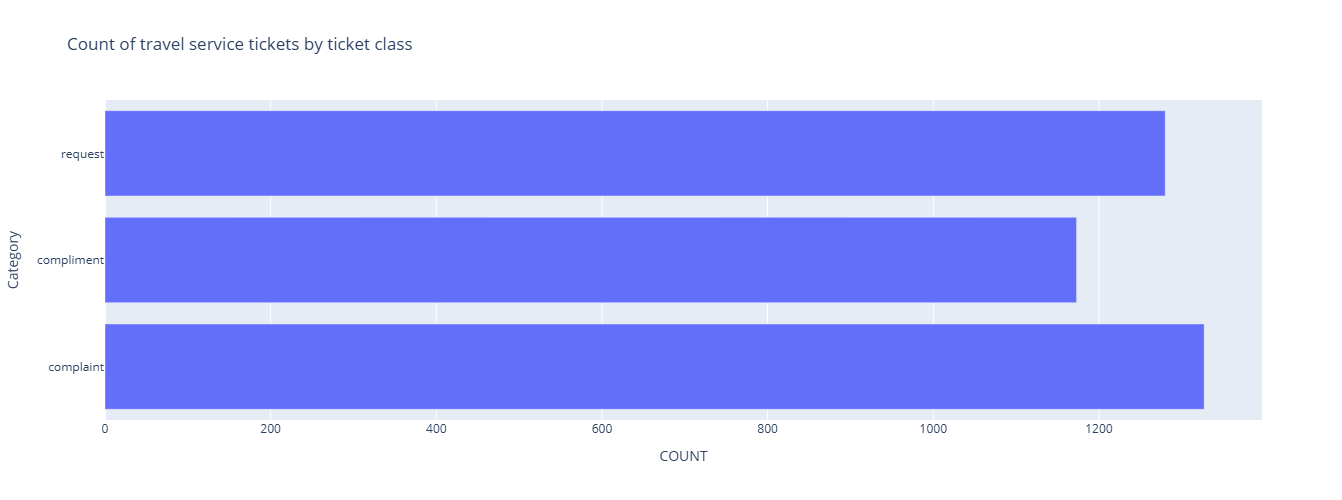

In [10]:
# Create a bar-chart visualization
from hana_ml.visualizers.eda import EDAVisualizer 
eda = EDAVisualizer(enable_plotly=True)

fig, bar = eda.bar_plot(data=travel_sti_hdf, 
                        column="Category", 
                        aggregation={'ID':'count'}, 
                        width=1200, height=500, orientation='h',
                        title="Count of travel service tickets by ticket class")

### Training, test data split for evaluating trained model

We split the loaded data into two sets
1. Data we should upload and do the training
2. Test data we use for testing the trained model

Sampling a __hold-out set__ from the training data for model evaluation

In [9]:
# Split the data into a model training- and a houl-out sample for testing the classification model
from hana_ml.algorithms.pal.partition import train_test_val_split
travel_sti_hdf_train, travel_sti_hdf_test, empty_val_hdf = train_test_val_split(data=travel_sti_hdf.select('ID', 'Description', 'Category'), partition_method='stratified', stratified_column='Category',
                                                       training_percentage=0.85,
                                                       testing_percentage=0.15,
                                                       validation_percentage=0.0)

print('Training data sample shape: ', travel_sti_hdf_train.shape)
print('The HANA dataframe result set shape: ',travel_sti_hdf_train.columns)
print('Testing, hold-out data sample shape: ',travel_sti_hdf_test.shape)

display(travel_sti_hdf_train.head(1).collect())
display(travel_sti_hdf_train.agg([('count', 'Description', 'COUNT')], group_by='Category').collect())
display(travel_sti_hdf_test.agg([('count', 'Description', 'COUNT')], group_by='Category').collect())

Training data sample shape:  [3213, 3]
Testing, hold-out data sample shape:  [567, 3]


,ID,Description,Category
0,1,how can a morning flight(5309) already be delayed 40 minutes due to traffic?! Insane &amp; happens all the time. ATL looking better,complaint


,Category,COUNT
0,request,1088
1,compliment,997
2,complaint,1128


,Category,COUNT
0,request,192
1,compliment,176
2,complaint,199


In [12]:
travel_sti_hdf_train.save("#TRAVEL_SERVICE_TICKETS_TRAIN", force=True)
travel_sti_hdf_test.save("#TRAVEL_SERVICE_TICKETS_TEST", force=True)
#itst_hdf_val.save("#TRAVEL_SERVICE_TICKETS_TRAIN_MINI", force=True)

### Building a AutoML classification model for IT Service Tickets

The only __feature column__ we want to feed into the model is the raw Text column __'Description'__.

In [19]:
class_features=['Description']

Now, create the __AutoML classifier__ model

In [16]:
# Creating the PAL AutoML classification scenario and general settings 
from hana_ml.algorithms.pal.auto_ml import AutomaticClassification

automl_class = AutomaticClassification(config_dict='default',      #'default', 'light', <custom> AutoML scenario configuration (selection of algorithms and paramters)  
                                       search_method='GA', population_size=25, generations=3,  offspring_size=15,
                                       successive_halving=False, 
                                       min_layer=2, 
                                       random_seed=20251105,
                                       scorings={"ACCURACY": 1.0, "AUC": 1.0}, fold_num=3, resampling_method='stratified_cv',
                                       elite_number=15
                                         )    

# Display the classifier algorithms and their configurations included in the AutoML task
#automl_class.display_config_dict(category="Classifier")

In [17]:
# Display the classifier algorithms and their configurations included in the AutoML task
#automl_class.display_config_dict(category="Classifier")

# For more targeted AutoML models, we strip down the AutoML operators to focus on the TextEmbedding- and some classification-operators only
automl_class.reset_config_dict(cc)

# Resampler
automl_class.delete_config_dict(category='Resampler')

# Transformer
automl_class.delete_config_dict('TargetEncoder') 
automl_class.delete_config_dict('LabelEncoder')
automl_class.delete_config_dict('OneHotEncoder')
automl_class.delete_config_dict('PolynomialFeatures')
automl_class.delete_config_dict('CATPCA')
automl_class.delete_config_dict('Imputer')
automl_class.delete_config_dict('SCALE')
automl_class.delete_config_dict('FS_unsupervised')
automl_class.delete_config_dict('FS_supervised')

# Adjusting the TextEmbedding-operator parameters
automl_class.update_config_dict('TextEmbedding', param_name='MODEL_VERSION', param_config=['SAP_GXY.20250407'])
automl_class.update_config_dict('TextEmbedding', param_name='PCA_DIM_NUM', param_config=[64, 128, 256])

##-Text Pipeline with TFIDF + TruncatedSVD
automl_class.update_config_dict('TFIDF', param_name='EMBED_DIM', param_config=[64, 128, 256])
#{"TFIDF": {"args": {"LANGUAGE":"EN", "EMBED_DIM":64}}},
##INSERT INTO PAL_PARAMETER_TAB VALUES ('CONFIG_MODIFY', null, null, '{"TFIDF":{"LANGUAGE":["EN"],"EMBED_DIM":[64, 128]}}');

# Classifier
automl_class.delete_config_dict('M_LOGR_Classifier')
automl_class.delete_config_dict('NB_Classifier')
automl_class.delete_config_dict('SVM_Classifier')
automl_class.delete_config_dict('DT_Classifier')

# Display final AutoML configuration
print(automl_class.display_config_dict())


          Used Operators     Category
0        HGBT_Classifier   Classifier
1  MLP_M_TASK_Classifier   Classifier
2         RDT_Classifier   Classifier
3          TextEmbedding  Transformer
4                  TFIDF  Transformer

------------------------------------------------------------

HGBT_Classifier
...............

       Param                        Config
0   ITER_NUM                         [100]
1  MAX_DEPTH         {'range': [1, 1, 11]}
2        ETA  [0.001, 0.01, 0.1, 0.5, 1.0]
3  NODE_SIZE         {'range': [1, 1, 21]}
------------------------------------------------------------

MLP_M_TASK_Classifier
.....................

                      Param                         Config
0              NETWORK_TYPE                            [0]
1  HIDDEN_LAYER_ACTIVE_FUNC                         [1, 2]
2         HIDDEN_LAYER_SIZE             [5, 5, 10, 10, 10]
3            TRAINING_STYLE                         [0, 1]
4             LEARNING_RATE  [0.001, 0.01, 0.1, 0.5, 0.99]


In [20]:
class_features

['Description']

In [61]:
# Start the AutoML process and visualize the progress in evaluating and finding a best possible classification model
from hana_ml.visualizers.automl_progress import PipelineProgressStatusMonitor

progress_status_monitor = PipelineProgressStatusMonitor(connection_context=cc, automatic_obj=automl_class)
progress_status_monitor.start()

automl_class.disable_workload_class_check()
automl_class.fit(data=travel_sti_hdf_train, key='ID', features=class_features, text_variable=class_features, label='Category', use_explain=False)   # the new parameter TEXT_VARIABLE 

automl_class.runtime #102-150secs secs with 3vCPUs

<IPython.core.display.Javascript object>

101.29319548606873

In [49]:
automl_class.best_pipeline_.collect()

,ID,PIPELINE,SCORES
0,0,"{""HGBT_Classifier"":{""args"":{""ITER_NUM"":100,""MAX_DEPTH"":6,""ETA"":0.1,""NODE_SIZE"":19},""inputs"":{""data"":{""TextEmbedding"":{""args"":{""MODEL_VERSION"":""SAP_GXY.20250407"",""PCA_DIM_NUM"":256},""inputs"":{""data"":""ROWDATA""}}}}}}","{""ACCURACY"":0.9197012138188608,""AUC"":0.9854316454250546,""F1_SCORE_complaint"":0.9018088692127474,""F1_SCORE_compliment"":0.9135824539455152,""F1_SCORE_request"":0.9430650821828435,""KAPPA"":0.8793180897962154,""LAYERS"":2.0,""MCC"":0.8796950932888135,""PRECISION_complaint"":0.9038737381996702,""PRECISION_compliment"":0.9377117498977853,""PRECISION_request"":0.9204062417203879,""RECALL_complaint"":0.899822695035461,""RECALL_compliment"":0.8906707912732008,""RECALL_request"":0.96691424541751,""SUPPORT_complaint"":376.0,""SUPPORT_compliment"":332.3333333333333,""SUPPORT_request"":362.6666666666667,""TIME"":4.258333333333333}"
1,1,"{""HGBT_Classifier"":{""args"":{""ITER_NUM"":100,""MAX_DEPTH"":9,""ETA"":0.1,""NODE_SIZE"":19},""inputs"":{""data"":{""TextEmbedding"":{""args"":{""MODEL_VERSION"":""SAP_GXY.20250407"",""PCA_DIM_NUM"":256},""inputs"":{""data"":""ROWDATA""}}}}}}","{""ACCURACY"":0.9206349206349206,""AUC"":0.9854214743268405,""F1_SCORE_complaint"":0.9001616339869187,""F1_SCORE_compliment"":0.9183406574364303,""F1_SCORE_request"":0.943156990363064,""KAPPA"":0.8807309563901344,""LAYERS"":2.0,""MCC"":0.88113931963982,""PRECISION_complaint"":0.9050926697823249,""PRECISION_compliment"":0.9411492463036874,""PRECISION_request"":0.9189016090564069,""RECALL_complaint"":0.8953900709219859,""RECALL_compliment"":0.8966858424689751,""RECALL_request"":0.968755866043661,""SUPPORT_complaint"":376.0,""SUPPORT_compliment"":332.3333333333333,""SUPPORT_request"":362.6666666666667,""TIME"":5.934333333333334}"
2,2,"{""HGBT_Classifier"":{""args"":{""ITER_NUM"":100,""MAX_DEPTH"":9,""ETA"":0.1,""NODE_SIZE"":14},""inputs"":{""data"":{""TextEmbedding"":{""args"":{""MODEL_VERSION"":""SAP_GXY.20250407"",""PCA_DIM_NUM"":256},""inputs"":{""data"":""ROWDATA""}}}}}}","{""ACCURACY"":0.9209461562402739,""AUC"":0.9853010194637042,""F1_SCORE_complaint"":0.9023058767123541,""F1_SCORE_compliment"":0.9151941929502733,""F1_SCORE_request"":0.9446027263698742,""KAPPA"":0.8811972018365276,""LAYERS"":2.0,""MCC"":0.8816428730676739,""PRECISION_complaint"":0.9076350775661121,""PRECISION_compliment"":0.9389465468087499,""PRECISION_request"":0.9191644854171499,""RECALL_complaint"":0.8971631205673759,""RECALL_compliment"":0.8926758083384589,""RECALL_request"":0.9715106869803002,""SUPPORT_complaint"":376.0,""SUPPORT_compliment"":332.3333333333333,""SUPPORT_request"":362.6666666666667,""TIME"":5.640666666666667}"
3,3,"{""HGBT_Classifier"":{""args"":{""ITER_NUM"":100,""MAX_DEPTH"":9,""ETA"":1.0,""NODE_SIZE"":19},""inputs"":{""data"":{""TextEmbedding"":{""args"":{""MODEL_VERSION"":""SAP_GXY.20250407"",""PCA_DIM_NUM"":256},""inputs"":{""data"":""ROWDATA""}}}}}}","{""ACCURACY"":0.9218798630563336,""AUC"":0.9843641160167772,""F1_SCORE_complaint"":0.9066948972724723,""F1_SCORE_compliment"":0.9140048465627907,""F1_SCORE_request"":0.9439812991077249,""KAPPA"":0.8826161510423477,""LAYERS"":2.0,""MCC"":0.8830119289286996,""PRECISION_complaint"":0.9130477331530437,""PRECISION_compliment"":0.9331760541158838,""PRECISION_request"":0.9214095116404762,""RECALL_complaint"":0.900709219858156,""RECALL_compliment"":0.895681826404718,""RECALL_request"":0.9678350557305855,""SUPPORT_complaint"":376.0,""SUPPORT_compliment"":332.3333333333333,""SUPPORT_request"":362.6666666666667,""TIME"":1.93}"
4,4,"{""HGBT_Classifier"":{""args"":{""ITER_NUM"":100,""MAX_DEPTH"":6,""ETA"":1.0,""NODE_SIZE"":14},""inputs"":{""data"":{""TextEmbedding"":{""args"":{""MODEL_VERSION"":""SAP_GXY.20250407"",""PCA_DIM_NUM"":256},""inputs"":{""data"":""ROWDATA""}}}}}}","{""ACCURACY"":0.9165888577653284,""AUC"":0.9850991958148546,""F1_SCORE_complaint"":0.8984128366010858,""F1_SCORE_compliment"":0.9149857581923628,""F1_SCORE_request"":0.9363306886080909,"

In [34]:
display(automl_class.get_best_pipeline())
#display(automl_class.get_optimal_config_dict())
#display(automl_class.get_optimal_connections())

'{"HGBT_Classifier":{"args":{"ITER_NUM":100,"MAX_DEPTH":6,"ETA":0.1,"NODE_SIZE":14},"inputs":{"data":{"TextEmbedding":{"args":{"MODEL_VERSION":"SAP_GXY.20250407","PCA_DIM_NUM":256},"inputs":{"data":"ROWDATA"}}}}}}'

### Evaluate the AutoML model quality using the score()-method and the hold-out sample

<br>

Apply the __score()-method__ with the __hold-out sample__, to __evaluate the model's "performance" (i.e. accuracy etc.)__ on data unseen during fitting of the model

In [62]:
score_pred_hdf, score_stats_hdf = automl_class.score( data=travel_sti_hdf_test, key='ID', features=class_features, label='Category')
automl_class.runtime #2.6 secs

2.730464458465576

In [41]:
print(automl_class.get_score_execute_statement())

DO (IN in_1 TABLE ("ROW_INDEX" INT, "MODEL_CONTENT" NVARCHAR(5000)) => "#PAL_AUTOML_MODEL_TBL_5_5891D0B2_A51E_11F1_BA68_F47B09A01846")
BEGIN
DECLARE param_name VARCHAR(5000) ARRAY;
DECLARE int_value INTEGER ARRAY;
DECLARE double_value DOUBLE ARRAY;
DECLARE string_value VARCHAR(5000) ARRAY;
params = UNNEST(:param_name, :int_value, :double_value, :string_value);
in_0 = SELECT "ID", "Description", "Category" FROM (SELECT a.* FROM #PAL_PARTITION_DATA_TBL_4357271B_A51B_11F1_927E_F47B09A01846 a inner join #PAL_PARTITION_RESULT_TBL_4357271B_A51B_11F1_927E_F47B09A01846 b        on a."ID" = b."ID" where b."PARTITION_TYPE" = 2) AS "DT_17";
CALL _SYS_AFL.PAL_PIPELINE_SCORE(:in_0, :in_1, :params, out_0, out_1, out_2, out_3);
CREATE LOCAL TEMPORARY COLUMN TABLE "#PAL_PIPELINE_SCORE_RESULT_TBL_5_122F4F99_A521_11F1_B29F_F47B09A01846" AS (SELECT * FROM :out_0);
CREATE LOCAL TEMPORARY COLUMN TABLE "#PAL_PIPELINE_SCORE_STATS_TBL_5_122F4F99_A521_11F1_B29F_F47B09A01846" AS (SELECT * FROM :out_1);
CREATE L

In [63]:
# Review the statistics - e.g. Accuracy and AUC
display(score_pred_hdf.collect())
display(score_stats_hdf.collect())

,ID,SCORE,CONFIDENCE,REASON_CODE,PLACEHOLDER_1,PLACEHOLDER_2
0,3,request,0.981898,None,None,None
1,12,complaint,0.999993,None,None,None
2,15,complaint,0.999665,None,None,None
3,34,complaint,0.999938,None,None,None
4,37,complaint,0.999147,None,None,None
...,...,...,...,...,...,...
562,3768,request,0.999953,None,None,None
563,3770,request,0.999986,None,None,None
564,3772,request,0.998924,None,None,None
565,3773,request,0.999947,None,None,None


,STAT_NAME,STAT_VALUE
0,ACCURACY,0.9206349206349206
1,AUC,0.9846993209721017
2,F1_SCORE_complaint,0.8877551020408162
3,F1_SCORE_compliment,0.9017341040462428
4,F1_SCORE_request,0.9696969696969697
5,KAPPA,0.8807676850752825
6,MCC,0.8812126743348896
7,PRECISION_complaint,0.9015544041450777
8,PRECISION_compliment,0.9176470588235294
9,PRECISION_request,0.9411764705882353


Visualize the classification __confusion matrix__ for the best AutoML pipeline model applied to the hold-out sample

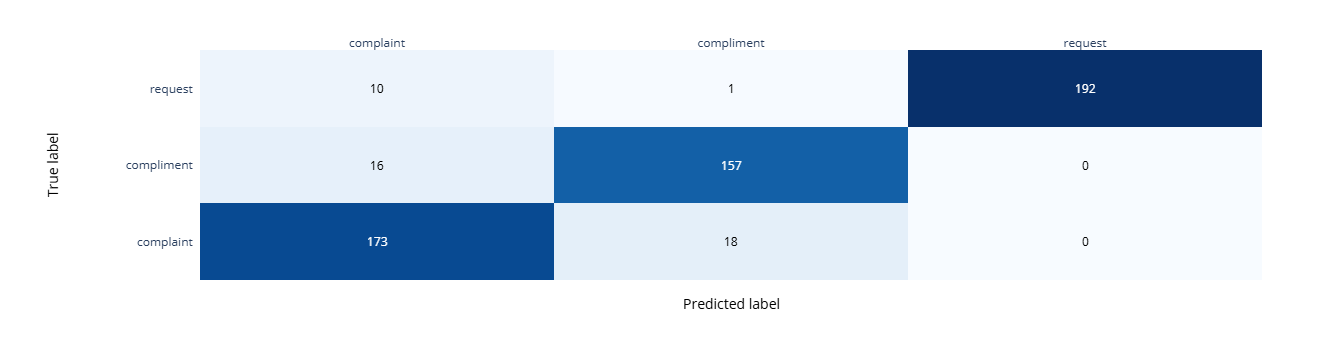

In [44]:
# Prepare a dataframe with incl. actual Ticket class categories and the predicted Ticket class categories
itst_score_mtrx_hdf=travel_sti_hdf_test.set_index("ID").join(score_pred_hdf.set_index("ID"))
itst_score_mtrx_hdf=itst_score_mtrx_hdf.rename_columns({'SCORE': 'PREDICTED_CLASS', 'Category': 'ACTUAL_CLASS'}).select('ID', 'ACTUAL_CLASS', 'PREDICTED_CLASS')

# Build the confusion matrix
from hana_ml.algorithms.pal import metrics
cm_df, classification_report_df = metrics.confusion_matrix(itst_score_mtrx_hdf, key='ID', label_true='ACTUAL_CLASS', label_pred='PREDICTED_CLASS')

# Plot the confustion matrix
from hana_ml.visualizers.metrics import MetricsVisualizer
cm_viz = MetricsVisualizer(show_plotly=False)
cm_viz.plot_confusion_matrix(df=cm_df, normalize=False) #normalize=False|True)

### Predicting with the AutoML classification model

 __Applying the AutoML classification model__ to __new tickets__ using the Predict()-method

In [71]:
# Apply the automl_class-model using the predict-method
hdf_predictions = automl_class.predict( data=travel_sti_hdf_test.drop('Category'), key='ID', features=class_features, show_explainer=False, verbose_output=True) #drop('LABEL_STR').sort("ID").head(10)

# Joining the prediction results with the original ticket-text column
hdf_result=travel_sti_hdf_test.select('ID', 'Description').set_index("ID").join(hdf_predictions.set_index("ID"))
hdf_result.rename_columns({'SCORES': 'PREDICTED_TICKET_CLASS'}).sort("ID").head(10).collect()
#hdf_result.rename_columns({'SCORE': 'PREDICTED_TICKET_CLASS'}).sort("ID").head(10).collect()

,ID,Description,PREDICTED_TICKET_CLASS
0,3,flight delayed due to paperwork confusion and then quarantined on the ground due to a passenger who was just airsick,request
1,12,The only thing worse than cancelling our flight for no reason is rude customer service who offer no help.,complaint
2,15,flight 1147 to #LA has been delayed AGAIN! Yesterday my flight was delayed twice then canceled. #overit #fail,complaint
3,34,"JFK, airport. Supervisor Velasquez is incompetent , rude. Disaster Disgusting what you did today #AmericanAirlines. Horror show",complaint
4,37,Customer service is a phrase that doesn't comprehend,complaint
5,40,booked flight with my wife and I sitting together. We're not. Attendant said she fixed it she didn't. Flight delayed over hour,complaint
6,42,"You are the worst airline! If you fly somewhere, have parts and maintenance crew there! Treat your customers better!",complaint
7,52,sitting in 1a on emb-145. Have a small backpack and flight attnd will not put it in their closet. bag is now in row 8. No CService,complaint
8,53,chg for bag w/ delta amex. horrible delays. bad experience!!!!!,complaint
9,60,Thank you for delaying my flight. There's nothing I want to do more then sit at a gate for another few hours.,complaint


In [72]:
hdf_predictions.sort('ID').head(7).collect()
#VERBOSE_OUTPUT

,ID,SCORES
0,1008,complaint
1,1011,complaint
2,1014,request
3,1016,complaint
4,1027,complaint
5,1038,complaint
6,1044,complaint


In [73]:
print(automl_class.get_predict_execute_statement())

DO (IN in_1 TABLE ("ROW_INDEX" INT, "MODEL_CONTENT" NVARCHAR(5000)) => "#PAL_AUTOML_MODEL_TBL_5_E163CB94_A52B_11F1_B3CC_F47B09A01846")
BEGIN
DECLARE param_name VARCHAR(5000) ARRAY;
DECLARE int_value INTEGER ARRAY;
DECLARE double_value DOUBLE ARRAY;
DECLARE string_value VARCHAR(5000) ARRAY;
params = UNNEST(:param_name, :int_value, :double_value, :string_value);
in_0 = SELECT "ID", "Description" FROM (SELECT "ID", "Description" FROM (SELECT a.* FROM #PAL_PARTITION_DATA_TBL_4357271B_A51B_11F1_927E_F47B09A01846 a inner join #PAL_PARTITION_RESULT_TBL_4357271B_A51B_11F1_927E_F47B09A01846 b        on a."ID" = b."ID" where b."PARTITION_TYPE" = 2) AS "DT_17") AS "DT_384";
CALL _SYS_AFL.PAL_PIPELINE_PREDICT(:in_0, :in_1, :params, out_0, out_1);
CREATE LOCAL TEMPORARY COLUMN TABLE "#PAL_AUTOML_RESULT_RESULT_TBL_5_C5CCA356_A52C_11F1_B628_F47B09A01846" AS (SELECT * FROM :out_0);
CREATE LOCAL TEMPORARY COLUMN TABLE "#PAL_AUTOML_INFO_RESULT_TBL_5_C5CCA356_A52C_11F1_B628_F47B09A01846" AS (SELECT * FRO

# Appendix